# Shared-time geometric 2BSDE: controlled three-state analytic benchmark

We keep the same control problem

$$
\Theta\in\{-1,0,1\},
\qquad
 dY_t=u_t\Theta\,dt+dW_t,
$$

with posterior

$$
d\pi_t^i
=
u_t\pi_t^i(\theta_i-\bar\theta_t)\,dI_t,
\qquad
\bar\theta_t=\sum_i\pi_t^i\theta_i.
$$

The running and terminal costs are chosen so that the exact solution is

$$
V(t,y,\pi)=\frac12(1-\|\pi\|^2),
\qquad
u^*\equiv1,
$$

with

$$
A\equiv0,
\qquad
\Gamma=
\begin{pmatrix}
0&0\\
0&-P_{\rm tan}
\end{pmatrix}.
$$

The architectural change is the main point of this notebook.  Instead of a separate network at each time slice,

$$
S_k\mapsto(A_k,\Gamma_k),
$$

we use **one shared time-conditioned map**

$$
(t,S)\mapsto(A(t,S),\Gamma(t,S)).
$$

The same block is used at every Euler step, including at $$t=0$$.  Thus $$A_0$$ and $$\Gamma_0$$ are no longer independent trainable parameters.

For this benchmark we use the fixed auxiliary control $$u^{\rm aux}\equiv1$$.  This is a solver/reference-process choice, not a change to the target control problem.  It is important here because $$u^{\rm aux}=0$$ freezes the posterior diffusion and gives almost no information for identifying the posterior Hessian.

In [23]:
from pathlib import Path
import math
import sys

import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from two_bsde import (
    BayesianControlProblem,
    GeometricClassicalFixedAux2BSDE,
    GeometricSharedTimeFixedAux2BSDE,
    HamiltonianConfig,
    HamiltonianOptimizer,
    ModelConfig,
    SimplexGeometry,
    TrainingConfig,
    evaluate,
    make_simplex_tangent_basis,
    split_state,
    state_dynamics,
    train,
)

DTYPE = torch.float64
DEVICE = torch.device("cpu")

torch.manual_seed(42)

## Configuration

The main training configuration below emphasizes the terminal gradient more strongly than the terminal value.  This does **not** directly supervise the Hessian, but the gradient recursion is the channel through which $$\Gamma$$ is learned.

In [24]:
config = ModelConfig(
    horizon=1.0,
    hidden_dim=1,
    observation_dim=1,
    control_dim=1,
    num_hidden_states=3,
    num_time_steps=100,
    network_width=64,
    network_depth=3,
    value_initial_guess=0.0,
    gamma_initial_scale=0.02,  # used by the classical model, not the shared model
)

ham_config = HamiltonianConfig(
    num_starts=4,
    num_steps=10,
    learning_rate=8e-2,
)

training_config = TrainingConfig(
    epochs=2000,
    batch_size=256,
    initial_value_lr=5e-2,
    learning_rate=5e-3,
    gradient_clip=10.0,
    value_loss_weight=1.0,
    gradient_loss_weight=2.0,
)

basis = make_simplex_tangent_basis(
    config.num_hidden_states,
    dtype=DTYPE,
    device=DEVICE,
)
geometry = SimplexGeometry(
    observation_dim=config.observation_dim,
    basis=basis,
)

print("dt =", config.dt)
print("state_dim =", config.state_dim)
print("tangent_dim =", config.tangent_dim)
print("gamma_parameter_dim =", config.gamma_parameter_dim)

dt = 0.01
state_dim = 4
tangent_dim = 2
gamma_parameter_dim = 6


## Concrete Bayesian control problem

In [25]:
class ControlledThreeStateProblem(BayesianControlProblem):
    def __init__(self, config, lam=1.0):
        super().__init__(config)
        self.lam = float(lam)

        self.x_support = torch.tensor(
            [[-1.0], [0.0], [1.0]],
            dtype=DTYPE,
            device=DEVICE,
        )
        self.theta = self.x_support[:, 0]

        self.initial_observation = torch.tensor(
            [0.0], dtype=DTYPE, device=DEVICE
        )
        self.initial_posterior = torch.tensor(
            [0.25, 0.50, 0.25], dtype=DTYPE, device=DEVICE
        )

        self.control_low = torch.tensor(
            [-1.0], dtype=DTYPE, device=DEVICE
        )
        self.control_high = torch.tensor(
            [1.0], dtype=DTYPE, device=DEVICE
        )

        # Fixed reference process.  u_aux=1 makes the posterior genuinely move.
        self.auxiliary_control_path = torch.ones(
            config.num_time_steps,
            config.control_dim,
            dtype=DTYPE,
            device=DEVICE,
        )

        self.validate()

    def sensor(self, control, observation):
        # h(u,y,theta_i)=u theta_i; y is unused in this example.
        lead = control.shape[:-1]
        theta = self.theta.reshape(
            *([1] * len(lead)),
            self.config.num_hidden_states,
            1,
        )
        return control.unsqueeze(-2) * theta

    def running_cost(self, state, control):
        _, p = split_state(state, self.config)
        theta_bar = (p * self.theta).sum(dim=-1, keepdim=True)
        base_B = p * (self.theta - theta_bar)
        u = control[..., 0]

        cancellation_term = (
            0.5 * u.square() * base_B.square().sum(dim=-1)
        )
        force_u_to_one = 0.5 * self.lam * (u - 1.0).square()
        return cancellation_term + force_u_to_one

    def terminal_cost(self, state):
        _, p = split_state(state, self.config)
        return 0.5 * (1.0 - p.square().sum(dim=-1))


problem = ControlledThreeStateProblem(config)
S0 = torch.cat(
    (problem.initial_observation, problem.initial_posterior)
)

print("S0 =", S0)
print("theta =", problem.theta)
print("auxiliary control =", problem.auxiliary_control_path[:, 0])

S0 = tensor([0.0000, 0.2500, 0.5000, 0.2500], dtype=torch.float64)
theta = tensor([-1.,  0.,  1.], dtype=torch.float64)
auxiliary control = tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1.], dtype=torch.float64)


## Exact solution and derivatives

In [26]:
def exact_value(state):
    _, p = split_state(state, config)
    return 0.5 * (1.0 - p.square().sum(dim=-1))


def exact_gradient(state):
    ambient = torch.zeros_like(state)
    ambient[..., config.observation_dim:] = -state[..., config.observation_dim:]
    return geometry.project_gradient(ambient)


def exact_hessian(state):
    shape = state.shape[:-1] + (config.state_dim, config.state_dim)
    gamma = torch.zeros(
        shape, dtype=state.dtype, device=state.device
    )
    m = config.observation_dim
    gamma[..., m:, m:] = -geometry.projector
    return gamma


def exact_control(state):
    return torch.ones(
        *state.shape[:-1],
        config.control_dim,
        dtype=state.dtype,
        device=state.device,
    )


V0_exact = exact_value(S0)
Z0_exact = exact_gradient(S0)
Gamma0_exact = exact_hessian(S0)

print("exact V0 =", V0_exact.item())
print("exact Z0 =", Z0_exact)
print("exact Gamma0 =")
print(Gamma0_exact)

exact V0 = 0.3125
exact Z0 = tensor([ 0.0000,  0.0833, -0.1667,  0.0833], dtype=torch.float64)
exact Gamma0 =
tensor([[ 0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000, -0.6667,  0.3333,  0.3333],
        [ 0.0000,  0.3333, -0.6667,  0.3333],
        [ 0.0000,  0.3333,  0.3333, -0.6667]], dtype=torch.float64)


## Verify the exact HJB using the generic dynamics

This check deliberately uses `state_dynamics`, rather than manually rebuilding the KS diffusion.  It therefore tests that the concrete `sensor` and the generic dynamics package agree with the analytic benchmark.

In [27]:
def analytic_hjb_expression(state, control):
    drift, sigma, _ = state_dynamics(
        state,
        control,
        problem=problem,
        config=config,
        geometry=geometry,
    )
    z = exact_gradient(state)
    gamma = exact_hessian(state)
    running = problem.running_cost(state, control)
    linear = (drift * z).sum(dim=-1)
    second_order = 0.5 * torch.einsum(
        "...ia,...ij,...ja->...",
        sigma,
        gamma,
        sigma,
    )
    return running + linear + second_order


test_states = torch.tensor(
    [
        [0.0, 0.20, 0.50, 0.30],
        [0.4, 0.70, 0.20, 0.10],
        [-0.6, 0.05, 0.20, 0.75],
    ],
    dtype=DTYPE,
    device=DEVICE,
)

u_exact = exact_control(test_states)
hjb_at_exact = analytic_hjb_expression(test_states, u_exact)
print("HJB at u=1:", hjb_at_exact)
assert torch.allclose(
    hjb_at_exact,
    torch.zeros_like(hjb_at_exact),
    atol=1e-12,
)

for u_value in [-1.0, -0.5, 0.0, 0.5]:
    u = torch.full(
        (len(test_states), config.control_dim),
        u_value,
        dtype=DTYPE,
        device=DEVICE,
    )
    value = analytic_hjb_expression(test_states, u)
    print(f"u={u_value:+.1f}, HJB terms={value.cpu().numpy()}")
    assert torch.all(value > 0)

print("analytic HJB check: PASSED")

HJB at u=1: tensor([7.6328e-17, 6.9389e-17, 2.0817e-17], dtype=torch.float64)
u=-1.0, HJB terms=[2. 2. 2.]
u=-0.5, HJB terms=[1.125 1.125 1.125]
u=+0.0, HJB terms=[0.5 0.5 0.5]
u=+0.5, HJB terms=[0.125 0.125 0.125]
analytic HJB check: PASSED


## Hamiltonian optimizer check with exact derivatives

In [28]:
hamiltonian_optimizer = HamiltonianOptimizer(
    problem=problem,
    model_config=config,
    optimizer_config=ham_config,
    geometry=geometry,
)

with torch.no_grad():
    z_batch = exact_gradient(test_states)
    gamma_batch = exact_hessian(test_states)
    h_from_exact, u_from_exact_derivatives = hamiltonian_optimizer.minimise(
        test_states,
        z_batch,
        gamma_batch,
    )

print("numerical u* from exact derivatives =", u_from_exact_derivatives[:, 0])
print("minimum Hamiltonian =", h_from_exact)
print(
    "max |u*-1| =",
    (u_from_exact_derivatives[:, 0] - 1.0).abs().max().item(),
)

numerical u* from exact derivatives = tensor([1., 1., 1.], dtype=torch.float64)
minimum Hamiltonian = tensor([7.6328e-17, 6.9389e-17, 2.0817e-17], dtype=torch.float64)
max |u*-1| = 0.0


## Build the shared-time model

For comparison we also instantiate the classical model only to count parameters.  We train the shared model below.

In [29]:
shared_model = GeometricSharedTimeFixedAux2BSDE(
    problem=problem,
    config=config,
    geometry=geometry,
    hamiltonian_optimizer=hamiltonian_optimizer,
).to(device=DEVICE, dtype=DTYPE)

classical_model = GeometricClassicalFixedAux2BSDE(
    problem=problem,
    config=config,
    geometry=geometry,
    hamiltonian_optimizer=hamiltonian_optimizer,
).to(device=DEVICE, dtype=DTYPE)


def num_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print("shared parameters   =", num_trainable_parameters(shared_model))
print("classical parameters=", num_trainable_parameters(classical_model))
print(
    "classical/shared ratio =",
    num_trainable_parameters(classical_model)
    / num_trainable_parameters(shared_model),
)

# We only train the shared model in this notebook.
del classical_model

print(shared_model)

shared parameters   = 17997
classical parameters= 1768648
classical/shared ratio = 98.27460132244263
GeometricSharedTimeFixedAux2BSDE(
  (shared_block): GeometricTimeConditionedBlock(
    (a_net): Sequential(
      (0): Linear(in_features=5, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
      (4): Linear(in_features=64, out_features=64, bias=True)
      (5): Tanh()
      (6): Linear(in_features=64, out_features=3, bias=True)
    )
    (gamma_net): Sequential(
      (0): Linear(in_features=5, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
      (4): Linear(in_features=64, out_features=64, bias=True)
      (5): Tanh()
      (6): Linear(in_features=64, out_features=6, bias=True)
    )
  )
)


## Train

In [30]:
history = train(
    shared_model,
    model_config=config,
    training_config=training_config,
    verbose=True,
)

epoch=   1  loss=2.585e-01  value=1.270e-01  grad=6.573e-02  V0=0.050000  corr=0.00e+00
epoch= 200  loss=9.125e-05  value=6.125e-05  grad=1.500e-05  V0=0.312239  corr=0.00e+00
epoch= 400  loss=8.882e-05  value=6.996e-05  grad=9.426e-06  V0=0.312017  corr=0.00e+00
epoch= 600  loss=7.525e-05  value=6.056e-05  grad=7.345e-06  V0=0.312423  corr=0.00e+00
epoch= 800  loss=1.561e-04  value=8.779e-05  grad=3.417e-05  V0=0.311837  corr=0.00e+00
epoch=1000  loss=6.947e-05  value=6.105e-05  grad=4.211e-06  V0=0.313330  corr=0.00e+00
epoch=1200  loss=7.583e-05  value=6.411e-05  grad=5.859e-06  V0=0.311313  corr=0.00e+00
epoch=1400  loss=6.217e-05  value=5.552e-05  grad=3.327e-06  V0=0.312374  corr=0.00e+00
epoch=1600  loss=8.820e-05  value=6.470e-05  grad=1.175e-05  V0=0.311861  corr=0.00e+00
epoch=1800  loss=6.108e-05  value=5.408e-05  grad=3.501e-06  V0=0.312792  corr=0.00e+00
epoch=2000  loss=7.386e-05  value=6.364e-05  grad=5.109e-06  V0=0.312023  corr=0.00e+00


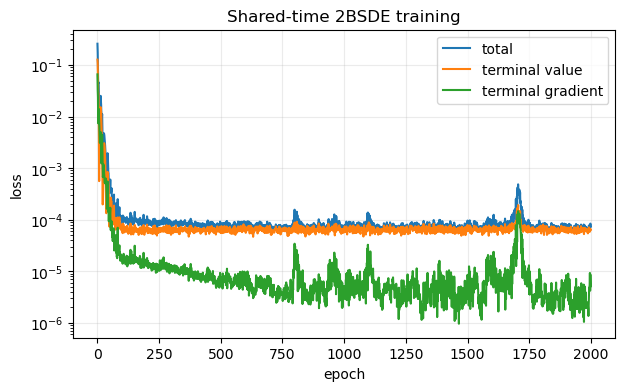

In [31]:
plt.figure(figsize=(7, 4))
plt.semilogy(history.total_loss, label="total")
plt.semilogy(history.value_loss, label="terminal value")
plt.semilogy(history.gradient_loss, label="terminal gradient")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Shared-time 2BSDE training")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Initial-point comparison

Unlike the classical model, `A0` and `Gamma0` are obtained from the shared map at $$(0,S_0)$$.

In [32]:
with torch.no_grad():
    V0_learned = shared_model.initial_value.detach()
    Z0_learned = shared_model.initial_gradient().detach()
    A0_learned, Gamma0_learned = shared_model.derivatives_at(
        0.0,
        S0[None, :],
    )
    A0_learned = A0_learned[0]
    Gamma0_learned = Gamma0_learned[0]

print("VALUE")
print(" learned:", V0_learned.item())
print(" exact:  ", V0_exact.item())
print(" abs err:", abs(V0_learned.item() - V0_exact.item()))

print()
print("GRADIENT")
print(" learned:", Z0_learned)
print(" exact:  ", Z0_exact)
print(" L2 err:", torch.linalg.vector_norm(Z0_learned - Z0_exact).item())

print()
print("DRIFT OF GRADIENT A")
print(" learned:", A0_learned)
print(" exact:   ", torch.zeros_like(A0_learned))
print(" L2 err:", torch.linalg.vector_norm(A0_learned).item())

print()
print("HESSIAN")
print(" learned:")
print(Gamma0_learned)
print(" exact:")
print(Gamma0_exact)
print(
    " Frobenius err:",
    torch.linalg.matrix_norm(Gamma0_learned - Gamma0_exact).item(),
)

VALUE
 learned: 0.3120233629617263
 exact:   0.3125
 abs err: 0.0004766370382737195

GRADIENT
 learned: tensor([-0.0031,  0.0109, -0.0325,  0.0216], dtype=torch.float64)
 exact:   tensor([ 0.0000,  0.0833, -0.1667,  0.0833], dtype=torch.float64)
 L2 err: 0.16453955163679132

DRIFT OF GRADIENT A
 learned: tensor([ 0.0044,  0.0847, -0.1613,  0.0766], dtype=torch.float64)
 exact:    tensor([0., 0., 0., 0.], dtype=torch.float64)
 L2 err: 0.19762592198238466

HESSIAN
 learned:
tensor([[ 0.0171,  0.0322, -0.0068, -0.0254],
        [ 0.0322, -0.3901,  0.2880,  0.1022],
        [-0.0068,  0.2880, -0.5912,  0.3032],
        [-0.0254,  0.1022,  0.3032, -0.4054]], dtype=torch.float64)
 exact:
tensor([[ 0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000, -0.6667,  0.3333,  0.3333],
        [ 0.0000,  0.3333, -0.6667,  0.3333],
        [ 0.0000,  0.3333,  0.3333, -0.6667]], dtype=torch.float64)
 Frobenius err: 0.5167186328186009


## Fresh-path evaluation of the shared derivatives

This is the central diagnostic.  Since the exact $$A$$ and $$\Gamma$$ are known everywhere in this example, we can measure their error along fresh auxiliary sample paths at every time step.

In [33]:
result = evaluate(shared_model, num_paths=500)
paths = result.paths

states_on_intervals = paths["S_path"][:, :-1, :]
A_exact_path = torch.zeros_like(paths["A_path"])
Gamma_exact_path = exact_hessian(states_on_intervals)
Z_exact_path = exact_gradient(paths["S_path"])
V_exact_path = exact_value(paths["S_path"])

A_error = torch.linalg.vector_norm(
    paths["A_path"] - A_exact_path,
    dim=-1,
)
Gamma_error = torch.linalg.matrix_norm(
    paths["Gamma_path"] - Gamma_exact_path,
    ord="fro",
    dim=(-2, -1),
)
Z_error = torch.linalg.vector_norm(
    paths["Z_path"] - Z_exact_path,
    dim=-1,
)
V_error = (paths["R_path"] - V_exact_path).abs()

u_star_path = paths["u_star_path"][..., 0]

print("evaluation diagnostics:", result.diagnostics)
print("mean |u*-1| =", (u_star_path - 1.0).abs().mean().item())
print("mean A error =", A_error.mean().item())
print("mean Gamma Frobenius error =", Gamma_error.mean().item())
print("mean Z error =", Z_error.mean().item())
print("mean V error =", V_error.mean().item())

evaluation diagnostics: {'posterior_correction_rate': 0.0, 'mean_u_star': 0.9829985000000001}
mean |u*-1| = 0.017001500000000013
mean A error = 0.18683827104279185
mean Gamma Frobenius error = 0.40591833573426556
mean Z error = 0.08360180356443826
mean V error = 0.004318685801627571


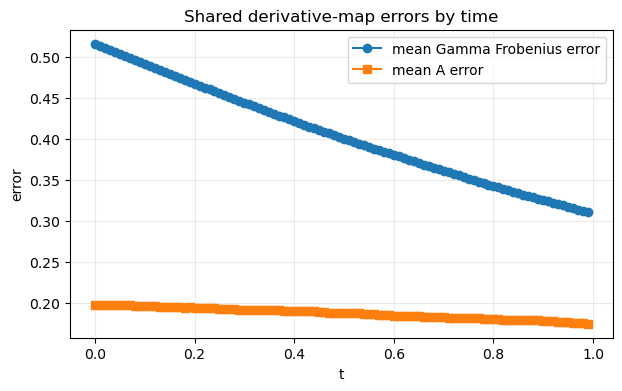

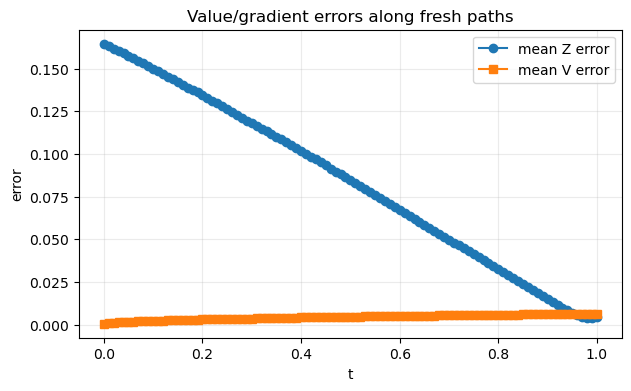

In [34]:
time_intervals = torch.arange(
    config.num_time_steps,
    dtype=DTYPE,
) * config.dt

time_states = torch.arange(
    config.num_time_steps + 1,
    dtype=DTYPE,
) * config.dt

plt.figure(figsize=(7, 4))
plt.plot(
    time_intervals.numpy(),
    Gamma_error.mean(dim=0).cpu().numpy(),
    marker="o",
    label="mean Gamma Frobenius error",
)
plt.plot(
    time_intervals.numpy(),
    A_error.mean(dim=0).cpu().numpy(),
    marker="s",
    label="mean A error",
)
plt.xlabel("t")
plt.ylabel("error")
plt.title("Shared derivative-map errors by time")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(
    time_states.numpy(),
    Z_error.mean(dim=0).cpu().numpy(),
    marker="o",
    label="mean Z error",
)
plt.plot(
    time_states.numpy(),
    V_error.mean(dim=0).cpu().numpy(),
    marker="s",
    label="mean V error",
)
plt.xlabel("t")
plt.ylabel("error")
plt.title("Value/gradient errors along fresh paths")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Mean learned Hessian at selected times

In [35]:
for step in [0, config.num_time_steps // 2, config.num_time_steps - 1]:
    mean_gamma = paths["Gamma_path"][:, step].mean(dim=0)
    print()
    print(f"t = {step * config.dt:.3f}")
    print("mean learned Gamma =")
    print(mean_gamma)
    print("exact Gamma =")
    print(Gamma0_exact)
    print(
        "Frobenius error of mean =",
        torch.linalg.matrix_norm(mean_gamma - Gamma0_exact).item(),
    )


t = 0.000
mean learned Gamma =
tensor([[ 0.0171,  0.0322, -0.0068, -0.0254],
        [ 0.0322, -0.3901,  0.2880,  0.1022],
        [-0.0068,  0.2880, -0.5912,  0.3032],
        [-0.0254,  0.1022,  0.3032, -0.4054]], dtype=torch.float64)
exact Gamma =
tensor([[ 0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000, -0.6667,  0.3333,  0.3333],
        [ 0.0000,  0.3333, -0.6667,  0.3333],
        [ 0.0000,  0.3333,  0.3333, -0.6667]], dtype=torch.float64)
Frobenius error of mean = 0.5167186328186008

t = 0.500
mean learned Gamma =
tensor([[ 0.0189,  0.0420, -0.0029, -0.0390],
        [ 0.0420, -0.4606,  0.3048,  0.1558],
        [-0.0029,  0.3048, -0.6122,  0.3074],
        [-0.0390,  0.1558,  0.3074, -0.4632]], dtype=torch.float64)
exact Gamma =
tensor([[ 0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000, -0.6667,  0.3333,  0.3333],
        [ 0.0000,  0.3333, -0.6667,  0.3333],
        [ 0.0000,  0.3333,  0.3333, -0.6667]], dtype=torch.float64)
Frobenius error of mean = 0.39975130183

## Interpretation

For this analytic problem, success means more than a small terminal loss.  The shared model should move toward all of

$$
V(t,S)=
rac12(1-\|\pi\|^2),\qquad
Z=D V,\qquad
A=0,\qquad
\Gamma=D^2V,
\qquad
u^*=1.
$$

The most informative comparison with the classical time-slice architecture is therefore the **time profile of the fresh-path Hessian error**, together with the parameter count.  If the terminal gradient error becomes small while the Hessian error remains large, parameter sharing alone has not solved the identifiability problem; the next step would be to impose additional derivative consistency rather than simply tuning the terminal loss.

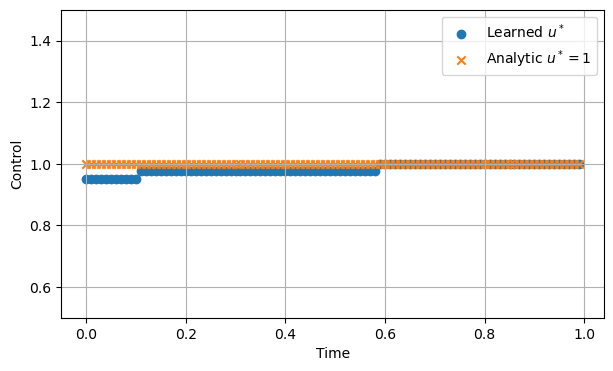

In [36]:
# Compare learned u* with analytic u*=1 using dots

result = evaluate(
    shared_model,
    num_paths=200,
)

sample = 0

u_learned = (
    result.paths["u_star_path"][sample, :, 0]
    .detach()
    .cpu()
)

times = torch.arange(
    config.num_time_steps,
    dtype=DTYPE,
) * config.dt

u_exact = torch.ones_like(u_learned)

plt.figure(figsize=(7, 4))

plt.scatter(
    times,
    u_learned,
    label="Learned $u^*$",
)

plt.scatter(
    times,
    u_exact,
    marker="x",
    label="Analytic $u^*=1$",
)

plt.xlabel("Time")
plt.ylabel("Control")
plt.ylim(0.5,1.5)
plt.legend()
plt.grid(True)
plt.show()